[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Why GeoPandas


## What you will be able to do

Turn a table of latitudes and longitudes into a GeoDataFrame, ask which district each row falls in,
count the rows in every district, and draw them on a map.

## The idea

### The problem

A weather service keeps a register of 300 stations: an id, a latitude and a longitude, an elevation,
an owner and the year each station was installed. The forecasters work in eight districts, and every
morning someone asks how many stations each district has, which district a new station belongs to,
and how far a station is from Oslo.

The **Pandas, Deep Dive** guide can filter, group and count that register, as long as the answer
depends on its columns. Which district a station is in does not depend on any column. It depends on
whether a point lies inside a shape, and a district's shape is a polygon of hundreds of corners.
Testing a point against one polygon takes a loop over its edges, and testing 300 points against eight
districts takes that loop 2,400 times, written and checked by hand. The distance to Oslo has a trap of
its own, because a degree of longitude is a different distance in Oslo and in the far north.

GeoPandas gives the register a column of shapes, so that these become questions about the table.

### A formal definition

> A **GeoDataFrame** is a pandas DataFrame with a **geometry column**, whose values are Shapely
> geometries (points, lines and polygons), and a **coordinate reference system** (CRS), which says
> what the numbers in those geometries mean, such as degrees of latitude and longitude or meters
> east and north of a fixed origin. Every DataFrame method still works, and spatial methods such as
> `area`, `distance` and `sjoin` act on the geometry column.

### Why it works that way

The geometry column holds one shape per row, and a spatial method runs once for the whole column, in
compiled code from the GEOS library, which Shapely wraps. Asking for `stations.within(district)` gives
a column of `True` and `False` as quickly as a comparison of numbers would, and `sjoin` matches every
station with the district that contains it in one call, the way `merge` matches rows on a key.

The CRS is what makes the numbers trustworthy. A point at longitude 10.75 and latitude 59.91 is Oslo
only because the CRS says the numbers are degrees on the WGS 84 ellipsoid. Two tables in different
systems describe the same place with different numbers, so GeoPandas keeps the CRS beside the
geometries and warns when two tables disagree. Distances and areas need a CRS in meters, and
`to_crs` converts a whole column to one.

A geometry column also brings habits that a plain table never needed: knowing which column is the
active geometry, keeping longitude before latitude, and checking that a shape is valid.

### Where this shows up

Any table with an address, a position or a region has a spatial question in it: stations and
districts, shops and delivery zones, sensors and rivers. The **Pandas, Deep Dive** guide's methods
apply unchanged, and the later notebooks in this guide take each spatial step in turn.

### What this notebook covers

- the register as a plain table, and the same table with a geometry column
- the countries and the forecast districts, and the CRS each one is in
- a spatial join that names each station's district, and a count by district
- distances from Oslo in kilometers
- a first map
- two mistakes made when a table first gets its geometry

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
import geopandas as gpd
from shapely.geometry import Point, box

zones = gpd.GeoDataFrame({"zone": ["A", "B"]}, geometry=[box(0, 0, 2, 2), box(2, 0, 4, 2)])
points = gpd.GeoDataFrame({"id": [1, 2, 3]}, geometry=[Point(1, 1), Point(3, 0.5), Point(5, 1)])
print(gpd.sjoin(points, zones, how="left")[["id", "zone"]])
```

```
   id zone
0   1    A
1   2    B
2   3  NaN
```

Two square zones sit side by side, and `sjoin` gives each point the zone it falls in. The third point
is outside both, and the left join keeps it with `NaN` for its zone.

## Setup

Two libraries for the tables, GeoPandas and Shapely for the geometry, and Matplotlib for the map.

- `Path` finds the guide's copy of the country outlines, when the notebook runs beside it
- `numpy` and `pandas` build the made-up register
- `geopandas` reads the outlines and does every spatial step, and the cell prints its version
- `shapely` is the geometry library under GeoPandas, used here to build the districts
- `matplotlib.pyplot` draws the map

`countries` holds the outlines of Denmark, Finland, Norway, Russia and Sweden, clipped to the Nordic
area. Made with Natural Earth. The outlines come from Natural Earth's 1:50m map of the world's
countries, which is in the public domain. The cell reads the copy in the guide's `data` folder when
there is one, and downloads it from the guide's repository otherwise, as in Colab.

`weather_stations` is the five named stations of the other guides at their real positions.
`station_network` makes the register of 300 stations, and `forecast_districts` makes the eight
districts. Both are made up. The stations are drawn at random over mainland Norway from a fixed seed,
so they are the same on every run, and the districts are drawn around eight chosen centers and cut to
Norway's outline.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
districts = forecast_districts()
print("geopandas", gpd.__version__, "| shapely", shapely.__version__, "|", len(countries), "countries,",
      len(network), "made-up stations,", len(districts), "made-up districts")

geopandas 1.2.0 | shapely 2.2.0 | 5 countries, 300 made-up stations, 8 made-up districts


## Worked examples

### The register as a plain table

In [2]:
print(type(network).__name__)
network.head()

DataFrame


,station,latitude,longitude,elevation_m,owner,installed
0,NS001,61.1793,10.6233,191,met,2019
1,NS002,64.8072,13.5681,325,met,2003
2,NS003,70.7203,24.4802,361,met,1956
3,NS004,69.8527,20.5569,402,road,1992
4,NS005,62.4479,12.1981,291,road,2003


The register is an ordinary DataFrame. `latitude` and `longitude` are two columns of numbers, and
nothing in the table knows they describe a place.

### Countries and districts with geometry already

`countries` came from a GeoJSON file, so it arrived as a GeoDataFrame with a geometry column and a CRS.

In [3]:
print(type(countries).__name__, "| CRS:", countries.crs)
countries[["ADMIN", "POP_EST"]].assign(shape=countries.geom_type)

GeoDataFrame | CRS: EPSG:4326


,ADMIN,POP_EST,shape
0,Denmark,5818553.0,MultiPolygon
1,Finland,5520314.0,MultiPolygon
2,Norway,5347896.0,MultiPolygon
3,Russia,144373535.0,MultiPolygon
4,Sweden,10285453.0,MultiPolygon


Each country is one row, and its shape is a `MultiPolygon`, a polygon made of several parts, since
every one of these countries has islands. EPSG:4326 is the code for WGS 84 latitude and longitude, so
the outlines are in degrees.

The districts are in another system.

In [4]:
print("CRS:", districts.crs.name, "| EPSG:", districts.crs.to_epsg())
districts.assign(area_km2=(districts.area / 1e6).round(0).astype(int)).drop(columns="geometry")

CRS: ETRS89 / UTM zone 33N | EPSG: 25833


,district,area_km2
0,South,36056
1,East,62504
2,West,53904
3,Mid,61575
4,North,30984
5,Far North,31283
6,Northeast,48523
7,Svalbard,62068


ETRS89 / UTM zone 33N measures in meters east and north, so `districts.area` is in square meters, and
dividing by a million gives square kilometers. The eight districts together cover 386,897 km², the area
of Norway's outline, Svalbard included.

### The register with a geometry column

`points_from_xy` turns two columns of numbers into a column of points. It takes x first, and for
latitude and longitude x is the longitude, east and west.

In [5]:
stations = gpd.GeoDataFrame(
    network,
    geometry=gpd.points_from_xy(network["longitude"], network["latitude"]),
    crs=4326,
)
print(type(stations).__name__, "| CRS:", stations.crs)
stations.head(3)

GeoDataFrame | CRS: EPSG:4326


,station,latitude,longitude,elevation_m,owner,installed,geometry
0,NS001,61.1793,10.6233,191,met,2019,POINT (10.6233 61.1793)
1,NS002,64.8072,13.5681,325,met,2003,POINT (13.5681 64.8072)
2,NS003,70.7203,24.4802,361,met,1956,POINT (24.4802 70.7203)


Every column of the register is still there, and a seventh, `geometry`, holds a point for each
station, written longitude first. `crs=4326` says the numbers are degrees.

### Which district each station is in

The districts are in meters and the stations in degrees, so the stations are converted to the
districts' CRS before the join. `sjoin` then matches each station with the district that contains it.

In [6]:
joined = gpd.sjoin(stations.to_crs(districts.crs), districts, how="left")
joined[["station", "owner", "district"]].head()

,station,owner,district
0,NS001,met,East
1,NS002,met,Mid
2,NS003,met,Northeast
3,NS004,road,Far North
4,NS005,road,Mid


In [7]:
counts = joined.groupby("district").size().reindex(districts["district"], fill_value=0)
print(counts)
print("total:", counts.sum())

district
South        32
East         56
West         43
Mid          69
North        27
Far North    25
Northeast    48
Svalbard      0
dtype: int64
total: 300


Mid has the most stations, 69, and Far North the fewest on the mainland, 25. All 300 stations have a
district, since every one of them was drawn on the mainland. Svalbard has none, and `reindex` with
`fill_value=0` keeps it in the count, which a plain `groupby` would leave out.

### The named stations and their countries

In [8]:
named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)
gpd.sjoin(named, countries[["ADMIN", "geometry"]], how="left")[["name", "ADMIN"]]

,name,ADMIN
0,Bergen,Norway
1,Oslo,Norway
2,Svalbard,Norway
3,Tromso,NaN
4,Kirkenes,NaN


Bergen, Oslo and Svalbard fall inside Norway's outline. Tromso and Kirkenes come back with no
country, although both are Norwegian towns. A 1:50m outline smooths the coast, and both towns stand on
the water's edge, so their points fall just outside it. The **Nearest Neighbors** notebook matches
such points to the closest shape instead.

### Distances from Oslo

`distance` measures in the units of the CRS. In UTM zone 33N those are meters, so dividing by 1,000
gives kilometers.

In [9]:
named_m = named.to_crs(25833)
oslo = named_m.geometry.iloc[1]
(named_m.distance(oslo) / 1000).round(0).astype(int).set_axis(named["name"])

name
Bergen       307
Oslo           0
Svalbard    2050
Tromso      1151
Kirkenes    1416
dtype: int64

Bergen is 307 km from Oslo, and Svalbard 2,050 km. The **Measuring Distance and Area** notebook
checks these against distances on the ellipsoid, and shows what the same call gives in degrees.

### A first map

`plot` draws a GeoDataFrame's geometry on a Matplotlib axes, and several layers drawn on the same
axes make a map. Everything is drawn in UTM zone 33N, so the countries are converted first.

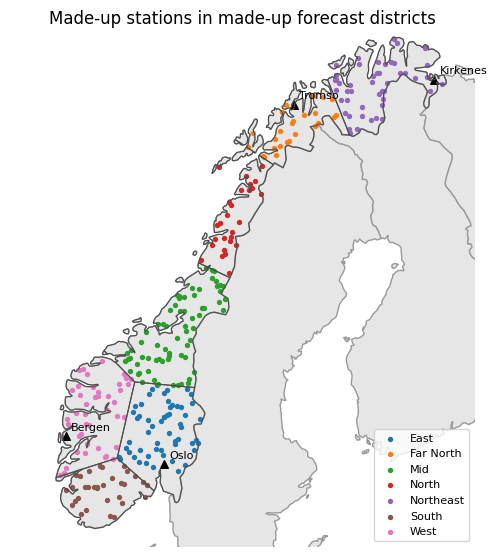

In [10]:
fig, ax = plt.subplots(figsize=(6, 7))
countries.to_crs(25833).plot(ax=ax, color="0.9", edgecolor="0.6")
districts.boundary.plot(ax=ax, color="0.3", linewidth=0.8)
joined.plot(ax=ax, column="district", categorical=True, markersize=8, legend=True,
            legend_kwds={"loc": "lower right", "fontsize": 8})
named_m.plot(ax=ax, color="black", marker="^", markersize=30)
for name, point in zip(named_m["name"], named_m.geometry):
    ax.annotate(name, (point.x, point.y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Made-up stations in made-up forecast districts")
plt.show()

The stations are colored by the district `sjoin` gave them, and each color stays inside its own
outline. The limits leave Svalbard off the map, since it lies far to the north and holds no stations.

The **Making Maps** notebook covers layers, colors and legends.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/01-why-geopandas-solutions.ipynb).

**1.** Count the network stations in the Mid district by `owner`, using `joined`.

In [11]:
# your code here

**2.** Print how many network stations were installed before 1970 in each district, with Svalbard shown as 0.

In [12]:
# your code here

**3.** Convert `countries` to UTM zone 33N and print Norway's area in square kilometers, rounded to a whole number.

In [13]:
# your code here

**4.** Find the network station farthest from Oslo, and print its id, its district and its distance in kilometers.

In [14]:
# your code here

**5.** Draw a map of the Mid district alone, with its outline and its stations.

In [15]:
# your code here

## Common errors

### `AttributeError: You are calling a geospatial method on the GeoDataFrame, but the active geometry column to use has not been set.`

`gpd.GeoDataFrame(network)` makes a GeoDataFrame, but the register has no geometry column yet, so there
is nothing for a spatial method to act on.

In [16]:
gpd.GeoDataFrame(network).area

AttributeError: You are calling a geospatial method on the GeoDataFrame, but the active geometry column to use has not been set. 
There are no existing columns with geometry data type. You can add a geometry column as the active geometry column with df.set_geometry. 

The message's next sentence says what to do, which is to give the table a geometry column, here
with `points_from_xy`, as the worked examples did. Holding a `latitude` and a `longitude` column is not
enough, because GeoPandas does not guess which columns are coordinates or in which order.

### No error, and 300 stations in no country

In [17]:
swapped = gpd.GeoDataFrame(
    network,
    geometry=gpd.points_from_xy(network["latitude"], network["longitude"]),
    crs=4326,
)
print(swapped.geometry.head(2))
found = gpd.sjoin(swapped, countries[["ADMIN", "geometry"]], how="left")
print("stations in a country:", found["ADMIN"].notna().sum())

0    POINT (61.1793 10.6233)
1    POINT (64.8072 13.5681)
Name: geometry, dtype: geometry
stations in a country: 0


`points_from_xy` takes x, then y. Given the latitude first, it puts the first station at longitude
61.18 and latitude 10.62, in the Arabian Sea, and no station lands in any of the five countries.
Nothing fails, because those numbers are valid coordinates somewhere on Earth. Pass the longitude
first, and check a few points against a place you know, as the map above does.

## Recap

- You can make a GeoDataFrame from a table of coordinates with `points_from_xy`, longitude first.
- You can read the CRS of a GeoDataFrame and convert it with `to_crs`.
- You can name the polygon each point falls in with `sjoin`, and count points per polygon with the
  empty ones kept.
- You can measure distances in kilometers in a CRS whose unit is the meter.
- You can draw several layers on one Matplotlib axes.

## What is next

The **Shapely Geometries** notebook looks at the points, lines and polygons inside a geometry column,
and the questions each one can answer.

---

[GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)  &nbsp;·&nbsp;  **Next:** [Shapely Geometries](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/02-shapely-geometries.ipynb) &#8594;
